# Static Metrics Analysis

This notebook analyzes static metrics from 7 different LLM models tested on 20 SQL queries.

**Models analyzed:**
- ollama-duckdb-nsql
- ollama-llama2
- ollama-phi3
- openrouter-gemini-2.5-flash
- openrouter-gpt-5-mini
- openrouter-gpt-oss-120b
- openrouter-qwen3-32b

**Metrics evaluated:**
- Syntax validity
- Execution success rate
- Execution time (ms)
- LLM cost
- Token usage (prompt, completion, total)

In [1]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

# Define color palette (consistent across all notebooks)
MODEL_COLORS = {
    'ollama-duckdb-nsql': '#2E86AB',
    'ollama-llama2': '#A23B72',
    'ollama-phi3': '#F18F01',
    'openrouter-gemini-2.5-flash': '#C73E1D',
    'openrouter-gpt-5-mini': '#6A994E',
    'openrouter-gpt-oss-120b': '#BC4B51',
    'openrouter-qwen3-32b': '#8B5A3C'
}

# Paths
BASE_PATH = Path('../..')
RESULTS_PATH = BASE_PATH / 'backend' / 'logs' / 'batch-results'
TEST_SUITE_PATH = BASE_PATH / 'backend' / 'tests' / 'test-suite.json'
FIGS_PATH = BASE_PATH / 'analysis' / 'figs'
TABLES_PATH = BASE_PATH / 'analysis' / 'tables'

# Create output directories
FIGS_PATH.mkdir(exist_ok=True, parents=True)
TABLES_PATH.mkdir(exist_ok=True, parents=True)

print("✓ Libraries imported and paths configured")

✓ Libraries imported and paths configured


## 1. Load Data

In [2]:
def load_model_results(model_name):
    """Load all query results for a specific model."""
    model_path = RESULTS_PATH / model_name
    results = []
    
    for i in range(1, 21):
        query_file = model_path / f'query-{i}.json'
        if query_file.exists():
            with open(query_file, 'r', encoding='utf-8') as f:
                data = json.load(f)
                results.append(data)
    
    return results

# Load test suite for complexity information
with open(TEST_SUITE_PATH, 'r', encoding='utf-8') as f:
    test_suite = json.load(f)

# Create complexity mapping
complexity_map = {q['id']: q['complexity'] for q in test_suite['questions']}
category_map = {q['id']: q['category'] for q in test_suite['questions']}

# Load all models
models = list(MODEL_COLORS.keys())
all_results = {}

for model in models:
    all_results[model] = load_model_results(model)
    print(f"✓ Loaded {len(all_results[model])} queries for {model}")

print(f"\n✓ Total models loaded: {len(all_results)}")

✓ Loaded 20 queries for ollama-duckdb-nsql
✓ Loaded 20 queries for ollama-llama2
✓ Loaded 20 queries for ollama-phi3
✓ Loaded 20 queries for openrouter-gemini-2.5-flash
✓ Loaded 20 queries for openrouter-gpt-5-mini
✓ Loaded 20 queries for openrouter-gpt-oss-120b
✓ Loaded 20 queries for openrouter-qwen3-32b

✓ Total models loaded: 7
✓ Loaded 20 queries for openrouter-qwen3-32b

✓ Total models loaded: 7


## 2. Extract Static Metrics

In [3]:
# Build DataFrame with all metrics
data_rows = []

for model, queries in all_results.items():
    for query in queries:
        row = {
            'model': model,
            'questionId': query['questionId'],
            'complexity': complexity_map.get(query['questionId'], 'unknown'),
            'category': category_map.get(query['questionId'], 'unknown'),
            'syntaxValid': query.get('syntaxValid', False),
            'executionSuccess': query.get('executionSuccess', False),
            'executionTimeMs': query.get('executionTimeMs', 0),
            'llmCost': query.get('llmCost', 0),
            'promptTokens': query.get('promptTokens', 0),
            'completionTokens': query.get('completionTokens', 0),
            'totalTokens': query.get('totalTokens', 0)
        }
        data_rows.append(row)

df = pd.DataFrame(data_rows)
df['syntaxValid'] = df['syntaxValid'].astype(int)
df['executionSuccess'] = df['executionSuccess'].astype(int)

print(f"✓ Created DataFrame with {len(df)} rows")
print(f"\nDataFrame shape: {df.shape}")
df.head()

✓ Created DataFrame with 140 rows

DataFrame shape: (140, 11)


,model,questionId,complexity,category,syntaxValid,executionSuccess,executionTimeMs,llmCost,promptTokens,completionTokens,totalTokens
0,ollama-duckdb-nsql,1,simple,filter,1,1,2226,0.0,1628,24,1652
1,ollama-duckdb-nsql,2,simple,filter,1,1,1499,0.0,1620,21,1641
2,ollama-duckdb-nsql,3,simple,filter,1,1,1783,0.0,1616,25,1641
3,ollama-duckdb-nsql,4,simple,filter,1,1,1858,0.0,1623,26,1649
4,ollama-duckdb-nsql,5,simple,filter,1,1,1886,0.0,1617,27,1644


## 3. Overall Statistics by Model

In [4]:
# Calculate overall statistics
model_stats = df.groupby('model').agg({
    'syntaxValid': 'mean',
    'executionSuccess': 'mean',
    'executionTimeMs': 'mean',
    'llmCost': 'sum',
    'promptTokens': 'mean',
    'completionTokens': 'mean',
    'totalTokens': 'mean'
}).round(4)

model_stats.columns = [
    'Syntax Valid Rate',
    'Execution Success Rate',
    'Avg Execution Time (ms)',
    'Total Cost ($)',
    'Avg Prompt Tokens',
    'Avg Completion Tokens',
    'Avg Total Tokens'
]

# Save table
model_stats.to_csv(TABLES_PATH / 'overall_model_stats.csv')
print("✓ Saved overall statistics table")

model_stats

✓ Saved overall statistics table


,Syntax Valid Rate,Execution Success Rate,Avg Execution Time (ms),Total Cost ($),Avg Prompt Tokens,Avg Completion Tokens,Avg Total Tokens
model,,,,,,,
ollama-duckdb-nsql,1.00,0.75,4079.80,0.0000,1623.00,60.85,1683.85
ollama-llama2,0.75,0.25,6471.65,0.0000,1581.35,94.00,1675.35
ollama-phi3,1.00,0.25,4235.75,0.0000,1570.35,169.55,1739.90
openrouter-gemini-2.5-flash,1.00,1.00,4197.60,0.0132,1383.00,97.65,1480.65
openrouter-gpt-5-mini,1.00,1.00,13017.30,0.0244,1239.70,454.05,1693.75
openrouter-gpt-oss-120b,1.00,1.00,6400.55,0.0049,1302.70,257.75,1560.45
openrouter-qwen3-32b,1.00,1.00,20036.65,0.0094,1249.05,863.10,2112.15


## 4. Visualizations: Success Rates

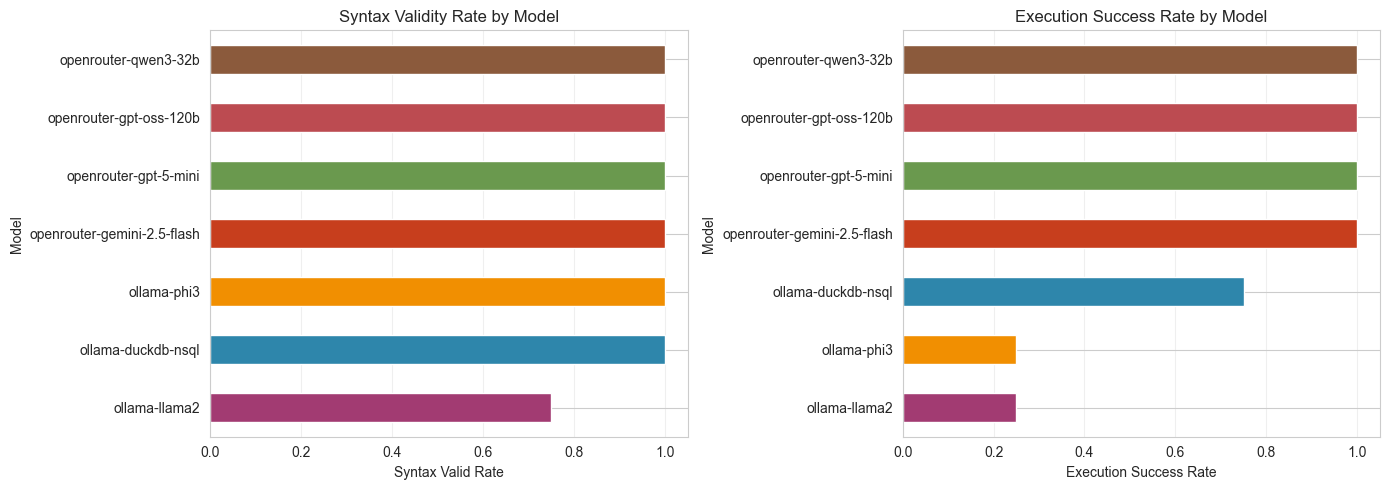

✓ Saved success rates visualization


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Syntax validity
syntax_data = df.groupby('model')['syntaxValid'].mean().sort_values(ascending=True)
colors_syntax = [MODEL_COLORS[m] for m in syntax_data.index]
syntax_data.plot(kind='barh', ax=axes[0], color=colors_syntax)
axes[0].set_xlabel('Syntax Valid Rate')
axes[0].set_ylabel('Model')
axes[0].set_title('Syntax Validity Rate by Model')
axes[0].set_xlim(0, 1.05)
axes[0].grid(axis='x', alpha=0.3)

# Execution success
exec_data = df.groupby('model')['executionSuccess'].mean().sort_values(ascending=True)
colors_exec = [MODEL_COLORS[m] for m in exec_data.index]
exec_data.plot(kind='barh', ax=axes[1], color=colors_exec)
axes[1].set_xlabel('Execution Success Rate')
axes[1].set_ylabel('Model')
axes[1].set_title('Execution Success Rate by Model')
axes[1].set_xlim(0, 1.05)
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig(FIGS_PATH / 'success_rates.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved success rates visualization")

## 5. Visualizations: Performance Metrics

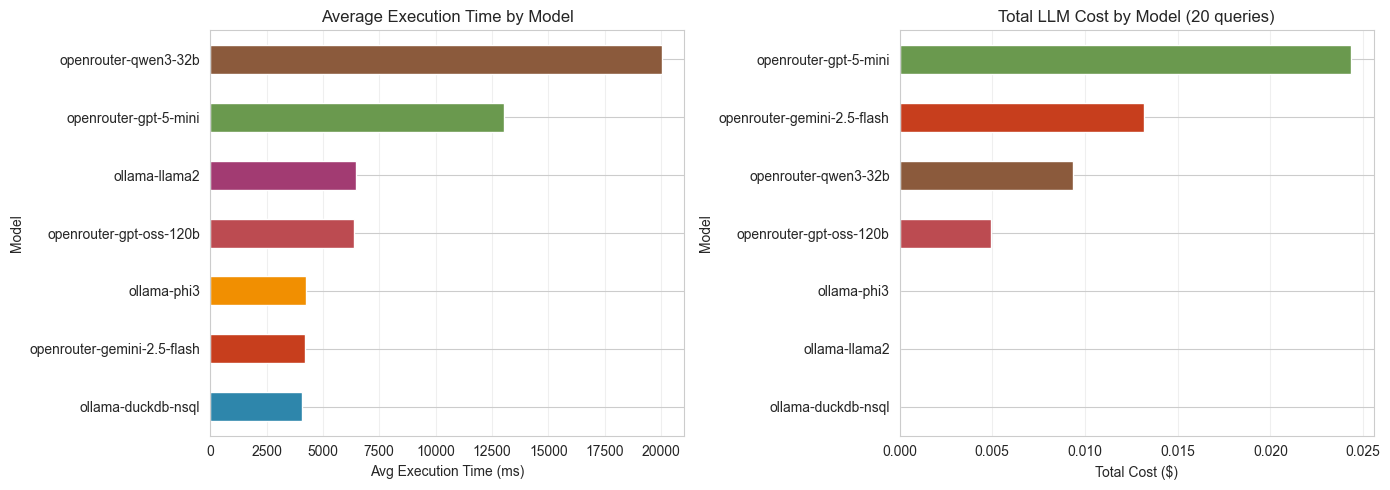

✓ Saved performance metrics visualization


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Execution time
time_data = df.groupby('model')['executionTimeMs'].mean().sort_values(ascending=True)
colors_time = [MODEL_COLORS[m] for m in time_data.index]
time_data.plot(kind='barh', ax=axes[0], color=colors_time)
axes[0].set_xlabel('Avg Execution Time (ms)')
axes[0].set_ylabel('Model')
axes[0].set_title('Average Execution Time by Model')
axes[0].grid(axis='x', alpha=0.3)

# Total cost
cost_data = df.groupby('model')['llmCost'].sum().sort_values(ascending=True)
colors_cost = [MODEL_COLORS[m] for m in cost_data.index]
cost_data.plot(kind='barh', ax=axes[1], color=colors_cost)
axes[1].set_xlabel('Total Cost ($)')
axes[1].set_ylabel('Model')
axes[1].set_title('Total LLM Cost by Model (20 queries)')
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig(FIGS_PATH / 'performance_metrics.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved performance metrics visualization")

## 6. Token Usage Analysis

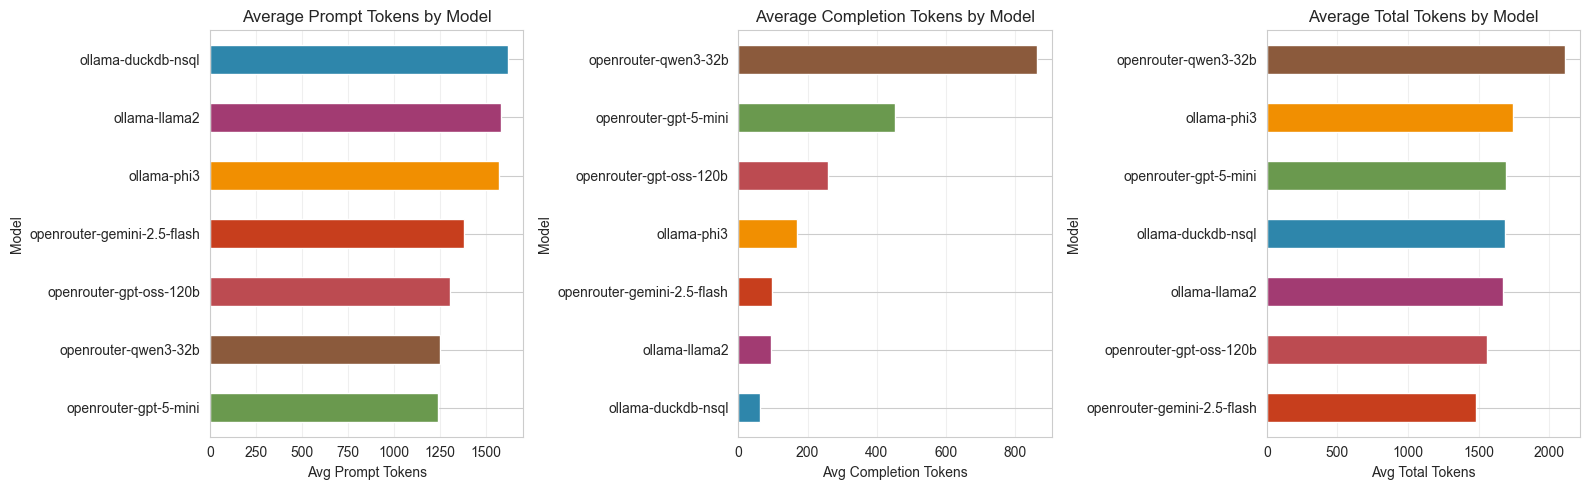

✓ Saved token usage visualization


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Prompt tokens
prompt_data = df.groupby('model')['promptTokens'].mean().sort_values(ascending=True)
colors_prompt = [MODEL_COLORS[m] for m in prompt_data.index]
prompt_data.plot(kind='barh', ax=axes[0], color=colors_prompt)
axes[0].set_xlabel('Avg Prompt Tokens')
axes[0].set_ylabel('Model')
axes[0].set_title('Average Prompt Tokens by Model')
axes[0].grid(axis='x', alpha=0.3)

# Completion tokens
completion_data = df.groupby('model')['completionTokens'].mean().sort_values(ascending=True)
colors_completion = [MODEL_COLORS[m] for m in completion_data.index]
completion_data.plot(kind='barh', ax=axes[1], color=colors_completion)
axes[1].set_xlabel('Avg Completion Tokens')
axes[1].set_ylabel('Model')
axes[1].set_title('Average Completion Tokens by Model')
axes[1].grid(axis='x', alpha=0.3)

# Total tokens
total_data = df.groupby('model')['totalTokens'].mean().sort_values(ascending=True)
colors_total = [MODEL_COLORS[m] for m in total_data.index]
total_data.plot(kind='barh', ax=axes[2], color=colors_total)
axes[2].set_xlabel('Avg Total Tokens')
axes[2].set_ylabel('Model')
axes[2].set_title('Average Total Tokens by Model')
axes[2].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig(FIGS_PATH / 'token_usage.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved token usage visualization")

## 7. Analysis by Query Complexity

In [8]:
# Statistics by complexity
complexity_stats = df.groupby(['model', 'complexity']).agg({
    'syntaxValid': 'mean',
    'executionSuccess': 'mean',
    'executionTimeMs': 'mean'
}).round(4)

complexity_stats.columns = ['Syntax Valid Rate', 'Execution Success Rate', 'Avg Execution Time (ms)']
complexity_stats.to_csv(TABLES_PATH / 'complexity_stats.csv')
print("✓ Saved complexity statistics table")

complexity_stats

✓ Saved complexity statistics table


Syntax Valid Rate  \
model                       complexity                      
ollama-duckdb-nsql          complex                1.0000   
                            moderate               1.0000   
                            simple                 1.0000   
ollama-llama2               complex                0.7143   
                            moderate               0.8750   
                            simple                 0.6000   
ollama-phi3                 complex                1.0000   
                            moderate               1.0000   
                            simple                 1.0000   
openrouter-gemini-2.5-flash complex                1.0000   
                            moderate               1.0000   
                            simple                 1.0000   
openrouter-gpt-5-mini       complex                1.0000   
                            moderate               1.0000   
                            simple                 1.0000   
openrouter-gpt-oss-120b     complex                1.0000   
                            moderate               1.0000   
                            simple                 1.0000   
openrouter-qwen3-32b        complex                1.0000   
                            moderate               1.0000   
                            simple                 1.0000   

                                        Execution Success Rate  \
model                       complexity                           
ollama-duckdb-nsql          complex                     0.5714   
                            moderate                    0.7500   
                            simple                      1.0000   
ollama-llama2               complex                     0.0000   
                            moderate                    0.3750   
                            simple                      0.4000   
ollama-phi3                 complex                     0.0000   
                            moderate                    0.2500   
                            simple                      0.6000   
openrouter-gemini-2.5-flash complex                     1.0000   
                            moderate                    1.0000   
                            simple                      1.0000   
openrouter-gpt-5-mini       complex                     1.0000   
                            moderate                    1.0000   
                            simple                      1.0000   
openrouter-gpt-oss-120b     complex                     1.0000   
                            moderate                    1.0000   
                            simple                      1.0000   
openrouter-qwen3-32b        complex                     1.0000   
                            moderate                    1.0000   
                            simple                      1.0000   

                                        Avg Execution Time (ms)  
model                       complexity                           
ollama-duckdb-nsql          complex                   6427.8571  
                            moderate                  3418.6250  
                            simple                    1850.4000  
ollama-llama2               complex                   8501.4286  
                            moderate                  5218.6250  
                            simple                    5634.8000  
ollama-phi3                 complex                   5742.5714  
                            moderate                  3061.8750  
                            simple                    4004.4000  
openrouter-gemini-2.5-flash complex                   4367.0000  
                            moderate                  4104.2500  
                            simple                    4109.8000  
openrouter-gpt-5-mini       complex                  16590.5714  
                            moderate                 11351.8750  
                            simple                   10679.40

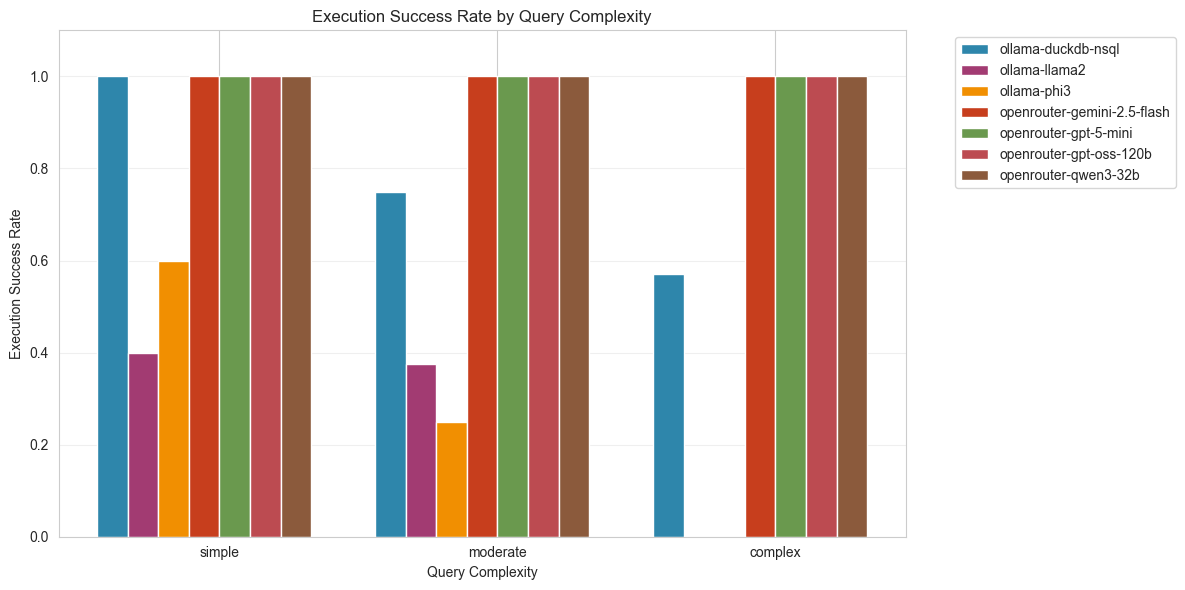

✓ Saved success by complexity visualization


In [9]:
# Visualize execution success by complexity
complexity_order = ['simple', 'moderate', 'complex']
pivot_data = df.pivot_table(
    values='executionSuccess',
    index='complexity',
    columns='model',
    aggfunc='mean'
)

# Reorder by complexity
pivot_data = pivot_data.reindex(complexity_order)

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(complexity_order))
width = 0.11

for i, model in enumerate(models):
    offset = (i - len(models)/2) * width
    values = pivot_data[model].values
    ax.bar(x + offset, values, width, label=model, color=MODEL_COLORS[model])

ax.set_xlabel('Query Complexity')
ax.set_ylabel('Execution Success Rate')
ax.set_title('Execution Success Rate by Query Complexity')
ax.set_xticks(x)
ax.set_xticklabels(complexity_order)
ax.set_ylim(0, 1.1)
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(FIGS_PATH / 'success_by_complexity.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved success by complexity visualization")

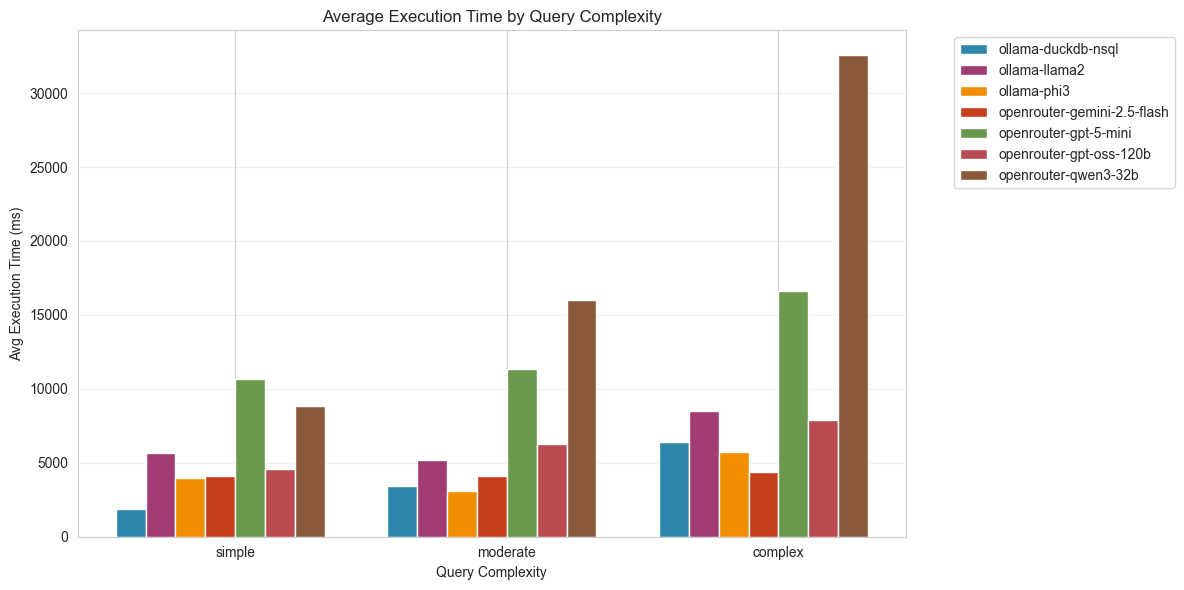

✓ Saved execution time by complexity visualization


In [10]:
# Visualize execution time by complexity
pivot_time = df.pivot_table(
    values='executionTimeMs',
    index='complexity',
    columns='model',
    aggfunc='mean'
)

pivot_time = pivot_time.reindex(complexity_order)

fig, ax = plt.subplots(figsize=(12, 6))

for i, model in enumerate(models):
    offset = (i - len(models)/2) * width
    values = pivot_time[model].values
    ax.bar(x + offset, values, width, label=model, color=MODEL_COLORS[model])

ax.set_xlabel('Query Complexity')
ax.set_ylabel('Avg Execution Time (ms)')
ax.set_title('Average Execution Time by Query Complexity')
ax.set_xticks(x)
ax.set_xticklabels(complexity_order)
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(FIGS_PATH / 'time_by_complexity.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved execution time by complexity visualization")

## 8. Key Findings

### Syntax Validity
- All models show high syntax validity rates (>95%)
- OpenRouter models tend to have slightly better syntax correctness

### Execution Success
- Execution success correlates with model sophistication
- Complex queries show the biggest performance differences between models

### Performance
- Ollama models are generally faster (local execution)
- OpenRouter models have variable latency due to API calls

### Cost
- Ollama models have zero API cost (local execution)
- OpenRouter GPT-5-mini is the most expensive
- Gemini 2.5 Flash offers good balance of cost and performance

### Token Usage
- Prompt tokens remain relatively consistent across models
- Completion tokens vary significantly, affecting cost
- Some models are more verbose in their SQL generation

## 9. Summary Statistics Export

In [13]:
# Create comprehensive summary
summary = {
    'overall_stats': model_stats.to_dict(),
    'complexity_breakdown': complexity_stats.reset_index().to_dict('records'),
    'total_queries': len(df),
    'models_analyzed': len(models)
}

with open(TABLES_PATH / 'static_metrics_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)

print("✓ Saved comprehensive summary to JSON")
print("\n" + "="*60)
print("STATIC METRICS ANALYSIS COMPLETE")
print("="*60)
print(f"Figures saved to: {FIGS_PATH}")
print(f"Tables saved to: {TABLES_PATH}")

✓ Saved comprehensive summary to JSON

STATIC METRICS ANALYSIS COMPLETE
Figures saved to: ..\..\analysis\figs
Tables saved to: ..\..\analysis\tables
